<b>ML Experiment 8: Implementation of Naive Bayes Classifier</b><br><br><b>Aim:</b> Apply Gaussian Naive Bayes on Iris measurements and Multinomial Naive Bayes with Bag-of-Words on IT support ticket routing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
iris = load_iris(as_frame=True)
xi_tr, xi_te, yi_tr, yi_te = train_test_split(
    iris.data, iris.target, test_size=0.25, stratify=iris.target, random_state=82
)

gauss_nb = GaussianNB()
gauss_nb.fit(xi_tr, yi_tr)
yi_pred = gauss_nb.predict(xi_te)
cv_acc = cross_val_score(GaussianNB(), iris.data, iris.target, cv=5).mean()

print("Part A - Gaussian Naive Bayes (Iris Dataset)")
print(f"Holdout Accuracy: {accuracy_score(yi_te, yi_pred):.4f} | 5-Fold CV Accuracy: {cv_acc:.4f}")
print(classification_report(yi_te, yi_pred, target_names=iris.target_names))

tickets = [
    "Invoice payment failed during credit card checkout",
    "Double charge appeared on monthly billing statement",
    "Need GST invoice PDF copy for annual subscription",
    "Refund amount pending after order cancellation",
    "Card declined error while renewing pro billing plan",
    "Update company tax ID on next billing invoice",
    "Subscription auto renewal charged twice on card",
    "Requesting refund receipt for cancelled billing cycle",
    "Payment gateway timeout during invoice settlement",
    "Download historical billing receipts from portal",
    "Server returns 502 gateway error on API endpoint",
    "Application crashes after login on Android device",
    "Database query timeout when exporting large CSV",
    "SSL certificate handshake failing on staging host",
    "Python SDK throws module import error on startup",
    "Dashboard filter dropdown freezes on Chrome browser",
    "Webhook retries failing with connection reset error",
    "Docker container memory spike during model inference",
    "REST endpoint latency exceeded timeout threshold",
    "Password reset link returns 404 page not found error",
]
ticket_labels = ["Billing"] * 10 + ["Technical"] * 10

Part A - Gaussian Naive Bayes (Iris Dataset)
Holdout Accuracy: 0.9211 | 5-Fold CV Accuracy: 0.9533
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



In [3]:
xt_tr, xt_te, yt_tr, yt_te = train_test_split(
    tickets, ticket_labels, test_size=0.25, stratify=ticket_labels, random_state=82
)

vec = CountVectorizer(stop_words="english")
xt_tr_bow = vec.fit_transform(xt_tr)
xt_te_bow = vec.transform(xt_te)

multi_nb = MultinomialNB(alpha=1.0)
multi_nb.fit(xt_tr_bow, yt_tr)
yt_pred = multi_nb.predict(xt_te_bow)

print("Part B - Multinomial Naive Bayes (Support Ticket Routing)")
print(f"Ticket Routing Test Accuracy: {accuracy_score(yt_te, yt_pred):.4f}")

sample_tickets = [
    "Invoice refund pending on credit card payment",
    "API endpoint throwing 502 connection timeout error",
]
sample_probs = multi_nb.predict_proba(vec.transform(sample_tickets))
for msg, probs in zip(sample_tickets, sample_probs):
    cls_name = multi_nb.classes_[int(np.argmax(probs))]
    print(f"Ticket: '{msg}' -> {cls_name} (Confidence: {np.max(probs):.4f})")

Part B - Multinomial Naive Bayes (Support Ticket Routing)
Ticket Routing Test Accuracy: 0.8000
Ticket: 'Invoice refund pending on credit card payment' -> Billing (Confidence: 0.9949)
Ticket: 'API endpoint throwing 502 connection timeout error' -> Technical (Confidence: 0.9865)


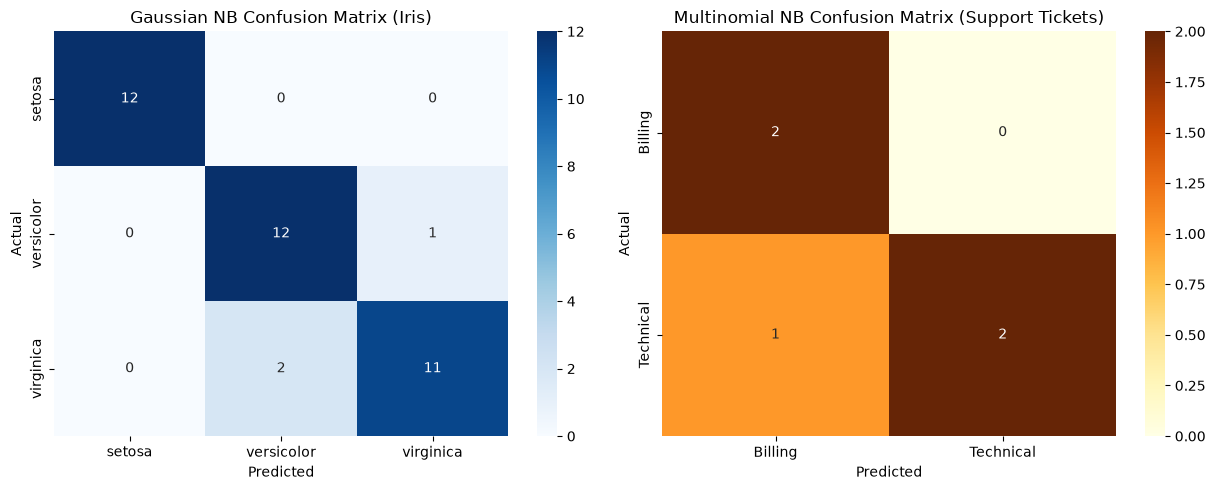

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5))

sns.heatmap(
    confusion_matrix(yi_te, yi_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=ax[0],
)
ax[0].set_title("Gaussian NB Confusion Matrix (Iris)")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(yt_te, yt_pred, labels=["Billing", "Technical"]),
    annot=True,
    fmt="d",
    cmap="YlOrBr",
    xticklabels=["Billing", "Technical"],
    yticklabels=["Billing", "Technical"],
    ax=ax[1],
)
ax[1].set_title("Multinomial NB Confusion Matrix (Support Tickets)")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

<b>Observation:</b> Gaussian Naive Bayes classifies continuous flower measurements accurately and Multinomial Naive Bayes routes Billing vs Technical tickets reliably.